<a href="https://colab.research.google.com/github/ambika261027-hue/Statiscs_Lab/blob/main/normal_distribution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
np.random.seed(42)

In [54]:
x = np.linspace(-4,4,400)

In [55]:
std_normal = stats.norm(0,1)

In [56]:
print('68-95-99.7')
print(f'P(-1<z<1) = {std_normal.cdf(1) - std_normal.cdf(-1):.6f}')
print(f'P(-2<z<2)= {std_normal.cdf(2)- std_normal.cdf(-2):.6f}')
print(f'P(-3<z<3)= {std_normal.cdf(3)- std_normal.cdf(-3):.6f}')


68-95-99.7
P(-1<z<1) = 0.682689
P(-2<z<2)= 0.954500
P(-3<z<3)= 0.997300


In [58]:
# Z-score Standardization
mu_exam,sigma_exam = 70,10
for score in [60,70,80,90]:
  z = (score - mu_exam)/ sigma_exam
  pct = std_normal.cdf(z) * 100
  print(f'Score={score}: Z={z:.2f},Percentile={pct:.1f}%')

Score=60: Z=-1.00,Percentile=15.9%
Score=70: Z=0.00,Percentile=50.0%
Score=80: Z=1.00,Percentile=84.1%
Score=90: Z=2.00,Percentile=97.7%


In [59]:
# ---- Exponential Distribution ----
lam = 1.0
exp_dist = stats.expon(scale=1/lam)
# Memoryless Property
print(f'Exp(lam=1):Mean={exp_dist.mean()},var = {exp_dist.var()}')
print(f'P(x>2) = {1 - exp_dist.cdf(2):.6f}')
print(f'P(x>3|x>1) = {(1 - exp_dist.cdf(3))/(1 - exp_dist.cdf(1)):.6f}')

Exp(lam=1):Mean=1.0,var = 1.0
P(x>2) = 0.135335
P(x>3|x>1) = 0.135335


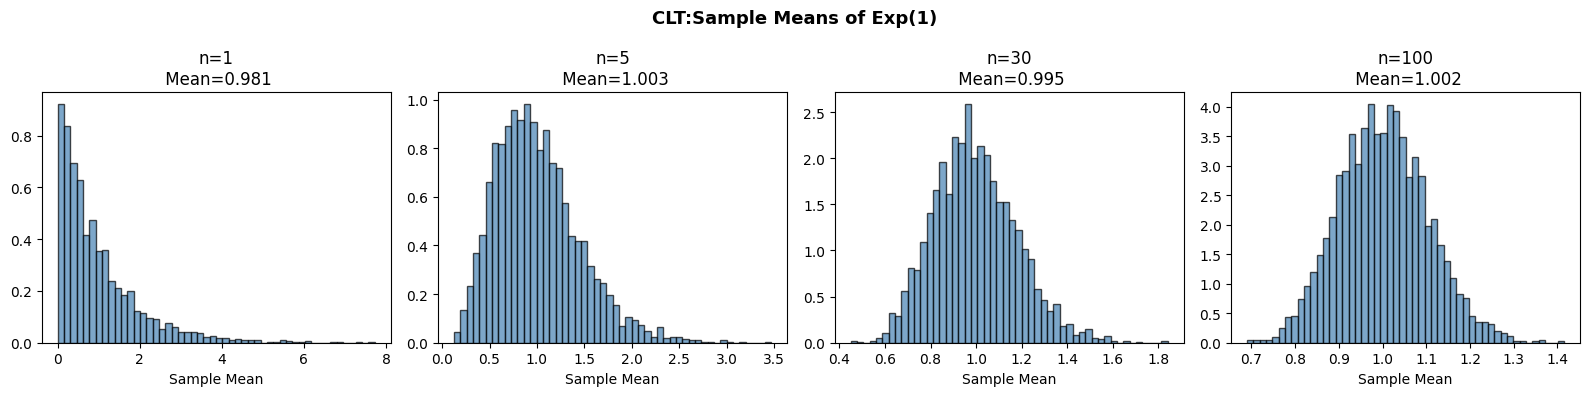

In [65]:
sample_sizes = [1,5,30,100]
fig,axes = plt.subplots(1,4,figsize=(16,4))
for i, n in enumerate(sample_sizes):
  means = [np.mean(np.random.exponential(1,n)) for _ in range(3000)]
  axes[i] .hist(means, bins=50, density=True, color='steelblue', edgecolor='black', alpha=0.7)
  axes[i].set_title(f'n={n}\n Mean={np.mean(means):.3f}')
  axes[i].set_xlabel('Sample Mean')
fig.suptitle('CLT:Sample Means of Exp(1)',fontsize=13,fontweight='bold')
plt.tight_layout();plt.show()